# Medicare Part D, New Jersey — Python check and charts

The SQL in `sql/` is the main analysis. This notebook does three things:
1. **Reconciles** pandas totals with the SQL results, so the numbers in the README are checked two ways.
2. **Re-derives** two headline numbers (brand vs generic split, generic-substitution savings) in pandas from the raw table.
3. **Draws the charts** used in the README (saved to `results/figures/`).

All costs are gross Part D costs **before manufacturer rebates**.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import text

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
from db import engine

eng = engine()
RESULTS = ROOT / "results"
FIG = RESULTS / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.float_format", "{:,.2f}".format)

## 1. Load the prescriber-drug table

In [2]:
cols = "data_year, prscrbr_npi, prscrbr_type, brnd_name, gnrc_name, is_brand, tot_clms, tot_day_suply, tot_drug_cst"
df = pd.read_sql(text(f"SELECT {cols} FROM prescriber_drug"), eng)
print(f"{len(df):,} rows")
df.head()

1,370,685 rows


,data_year,prscrbr_npi,prscrbr_type,brnd_name,gnrc_name,is_brand,tot_clms,tot_day_suply,tot_drug_cst
0,2023,1003001678,Nurse Practitioner,Clobetasol Propionate,Clobetasol Propionate,False,14,182,149.20
1,2023,1003001678,Nurse Practitioner,Estradiol,Estradiol,False,35,2550,"5,922.83"
2,2023,1003001678,Nurse Practitioner,Nitrofurantoin Mono-Macro,Nitrofurantoin Monohyd/M-Cryst,False,12,71,151.66
3,2023,1003001678,Nurse Practitioner,Valacyclovir,Valacyclovir Hcl,False,13,1000,861.27
4,2023,1003002072,Urology,Finasteride,Finasteride,False,51,3055,723.75


## 2. Reconcile with SQL (Q0 overview)
If pandas and SQL disagree here, one of them is wrong.

In [3]:
py = (df.groupby("data_year")
        .agg(prescribers=("prscrbr_npi", "nunique"), claims=("tot_clms", "sum"), cost=("tot_drug_cst", "sum"))
        .reset_index())
sql = pd.read_csv(RESULTS / "q0_overview.csv")
check = py.merge(sql, on="data_year", suffixes=("_py", "_sql"))
check["cost_musd_py"] = check["cost"] / 1e6
check["claims_match"] = check["claims_py"] == check["claims_sql"]
check["cost_match"] = (check["cost_musd_py"].round(1) - check["cost_musd"]).abs() < 0.05
check[["data_year", "claims_py", "claims_sql", "claims_match", "cost_musd_py", "cost_musd", "cost_match"]]

,data_year,claims_py,claims_sql,claims_match,cost_musd_py,cost_musd,cost_match
0,2023,33933535,33933535,True,"5,958.28","5,958.30",True
1,2024,36124998,36124998,True,"6,263.64","6,263.60",True


In [4]:
assert check["claims_match"].all() and check["cost_match"].all(), "pandas and SQL totals disagree"
print("Totals reconcile.")

Totals reconcile.


## 3. Brand vs generic, re-derived in pandas (compare with Q3)

In [5]:
bg = (df.assign(product_type=df["is_brand"].map({True: "Brand", False: "Generic"}))
        .groupby(["data_year", "product_type"])[["tot_clms", "tot_drug_cst"]].sum())
bg["pct_of_claims"] = 100 * bg["tot_clms"] / bg.groupby(level=0)["tot_clms"].transform("sum")
bg["pct_of_cost"] = 100 * bg["tot_drug_cst"] / bg.groupby(level=0)["tot_drug_cst"].transform("sum")
bg

tot_clms     tot_drug_cst  pct_of_claims  pct_of_cost
data_year product_type                                                       
2023      Brand          4337062 5,066,423,687.89          12.78        85.03
          Generic       29596473   891,852,589.95          87.22        14.97
2024      Brand          4611356 5,506,417,639.18          12.77        87.91
          Generic       31513642   757,217,520.72          87.23        12.09

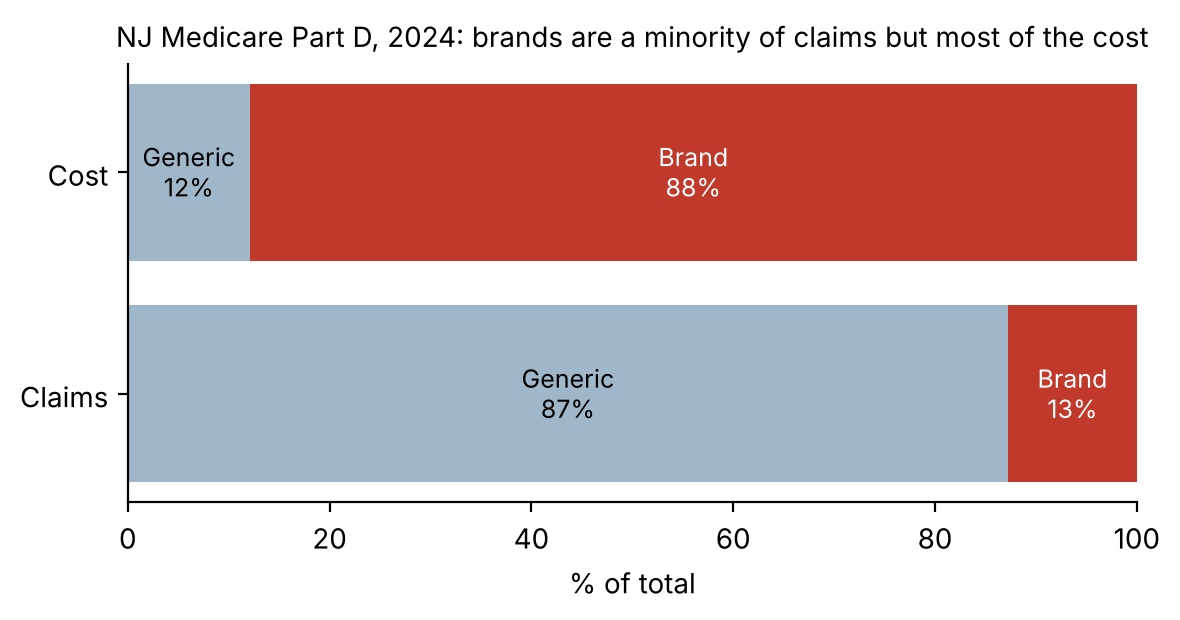

In [6]:
latest = df["data_year"].max()
b = bg.loc[latest]
fig, ax = plt.subplots(figsize=(6, 3.2))
left = 0
colors = {"Generic": "#9fb7c9", "Brand": "#c0392b"}
for metric, y in [("pct_of_claims", "Claims"), ("pct_of_cost", "Cost")]:
    left = 0
    for pt in ["Generic", "Brand"]:
        v = b.loc[pt, metric]
        ax.barh(y, v, left=left, color=colors[pt], label=pt if metric == "pct_of_claims" else None)
        ax.text(left + v / 2, y, f"{pt}\n{v:.0f}%", ha="center", va="center", fontsize=9,
                color="white" if pt == "Brand" else "black")
        left += v
ax.set_xlim(0, 100)
ax.set_xlabel("% of total")
ax.set_title(f"NJ Medicare Part D, {latest}: brands are a minority of claims but most of the cost", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIG / "brand_vs_generic.png", dpi=150)
plt.show()

## 4. Top drugs by spend (from Q1)

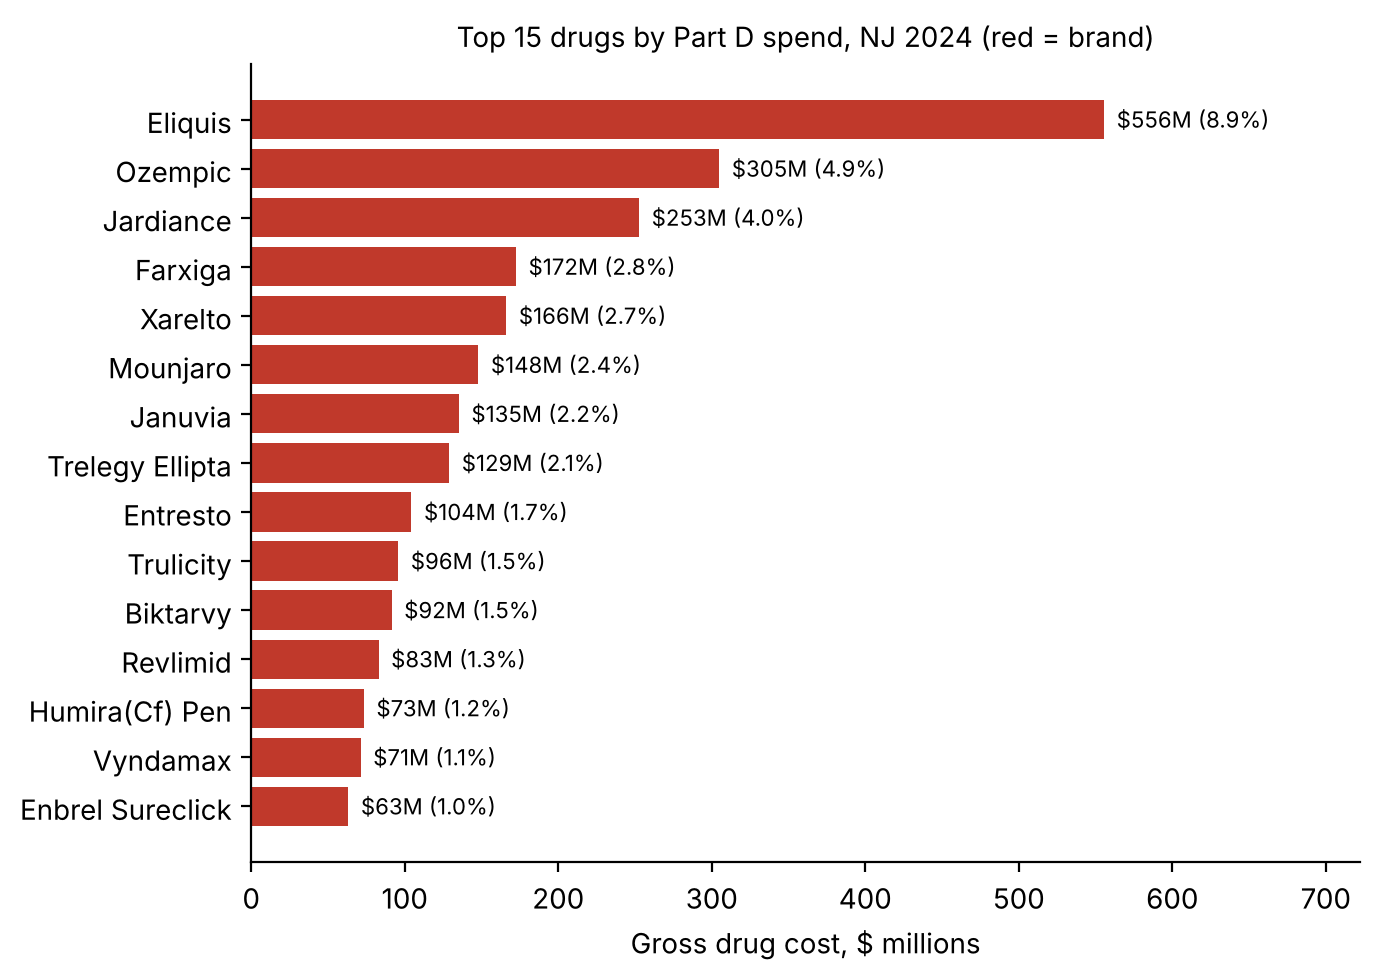

In [7]:
top = pd.read_csv(RESULTS / "q1_top_drugs_by_spend.csv").head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top["brnd_name"], top["cost_musd"], color=["#c0392b" if b else "#7f8c8d" for b in top["is_brand"]])
for y, (v, s) in enumerate(zip(top["cost_musd"], top["pct_of_spend"])):
    ax.text(v, y, f"  ${v:,.0f}M ({s:.1f}%)", va="center", fontsize=8)
ax.set_xlabel("Gross drug cost, $ millions")
ax.set_title(f"Top 15 drugs by Part D spend, NJ {latest} (red = brand)", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
ax.set_xlim(0, top["cost_musd"].max() * 1.3)
plt.tight_layout()
plt.savefig(FIG / "top_drugs.png", dpi=150)
plt.show()

## 5. Generic-substitution savings, re-derived in pandas (compare with Q5b)

For each molecule sold as both brand and generic: brand days of supply × (brand cost per day − generic cost per day).

In [8]:
cur = df[df["data_year"] == latest]
mol = (cur.groupby(["gnrc_name", "is_brand"])[["tot_day_suply", "tot_drug_cst"]].sum()
          .unstack("is_brand").dropna())
mol.columns = [f"{m}_{'brand' if b else 'generic'}" for m, b in mol.columns]
mol = mol[(mol["tot_day_suply_brand"] > 0) & (mol["tot_day_suply_generic"] > 0)]
mol["brand_per_day"] = mol["tot_drug_cst_brand"] / mol["tot_day_suply_brand"]
mol["generic_per_day"] = mol["tot_drug_cst_generic"] / mol["tot_day_suply_generic"]
mol["savings"] = (mol["tot_day_suply_brand"] * (mol["brand_per_day"] - mol["generic_per_day"])).clip(lower=0)

# Same manual exclusions as SQL (molecules where brand and generic are different formulations)
excl = pd.read_sql(text("SELECT gnrc_name, reason FROM substitution_exclusions"), eng)
mol["excluded"] = mol.index.isin(excl["gnrc_name"])

sql = pd.read_csv(RESULTS / "q5b_generic_substitution_total.csv").iloc[0]
py_raw, py_reviewed = mol["savings"].sum() / 1e6, mol.loc[~mol["excluded"], "savings"].sum() / 1e6
print(f"raw:      pandas ${py_raw:,.1f}M   SQL ${sql['raw_savings_musd']:,.1f}M")
print(f"reviewed: pandas ${py_reviewed:,.1f}M   SQL ${sql['est_savings_musd']:,.1f}M")
assert abs(py_raw - sql["raw_savings_musd"]) < 0.1 and abs(py_reviewed - sql["est_savings_musd"]) < 0.1
mol.loc[~mol["excluded"]].sort_values("savings", ascending=False).head(10)[["brand_per_day", "generic_per_day", "savings"]]

raw:      pandas $295.1M   SQL $295.1M
reviewed: pandas $197.8M   SQL $197.8M


,brand_per_day,generic_per_day,savings
gnrc_name,,,
Lenalidomide,626.90,478.82,"19,604,496.87"
Insulin Degludec,12.34,4.31,"19,032,722.14"
Mirabegron,14.85,10.37,"16,496,568.26"
Icosapent Ethyl,10.13,5.97,"11,162,281.89"
Dapagliflozin Propanediol,18.21,17.15,"9,981,282.39"
Levothyroxine Sodium,0.97,0.16,"8,206,731.82"
Oxycodone Hcl/Acetaminophen,57.10,0.98,"7,271,368.67"
Dasatinib,457.83,186.27,"6,222,483.06"
Insulin Lispro,5.79,3.66,"5,790,915.45"


## 6. Spend growth by therapeutic group (from Q7)

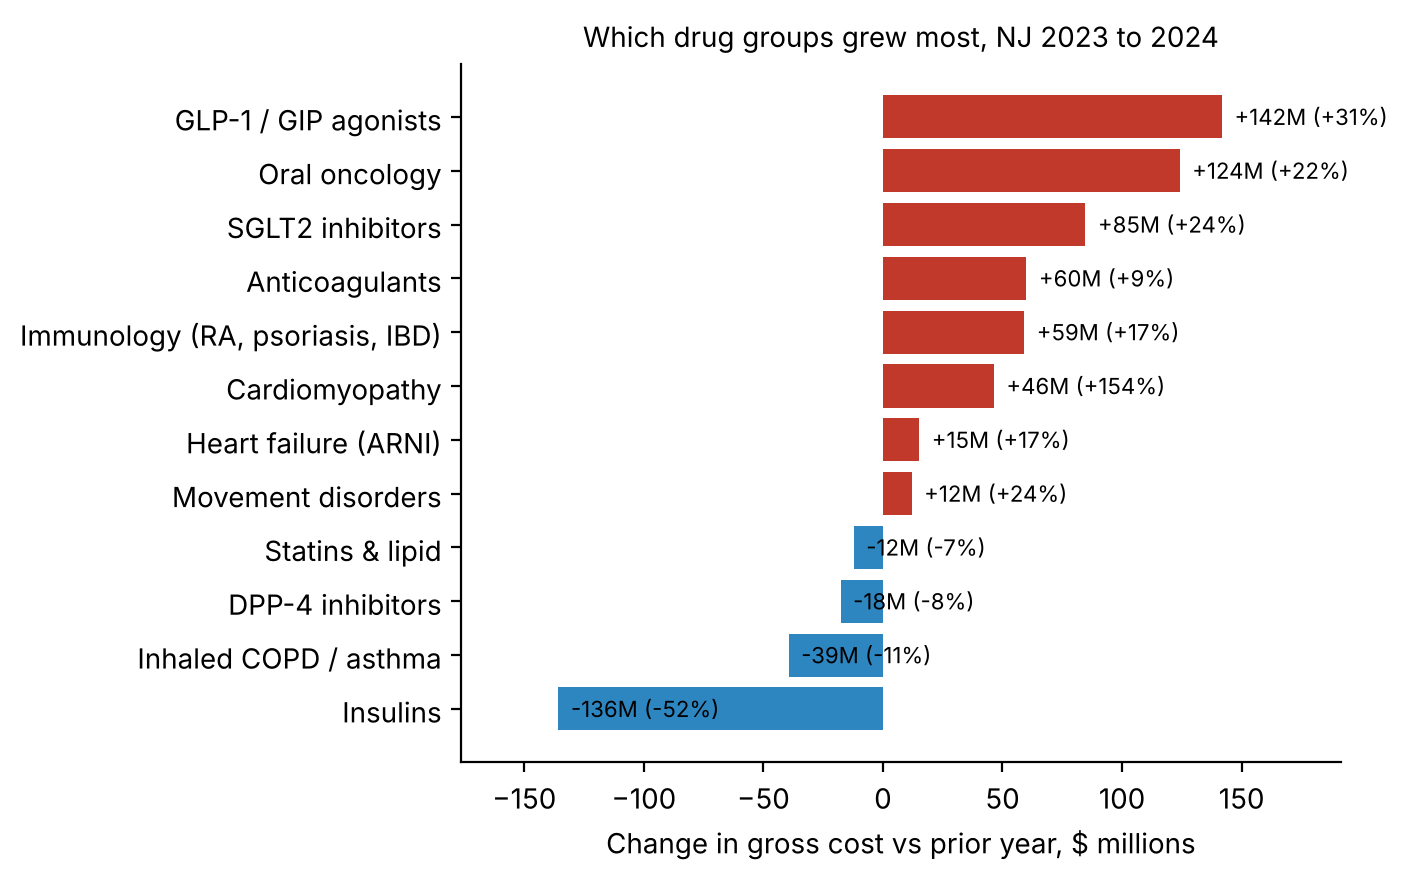

In [9]:
grp = pd.read_csv(RESULTS / "q7_spend_by_group.csv")
grp = grp[grp["drug_group"] != "Other / unmapped"].sort_values("change_musd")
grp = pd.concat([grp.head(4), grp.tail(8)])   # 4 biggest decreases + 8 biggest increases
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(grp["drug_group"], grp["change_musd"], color=["#c0392b" if v > 0 else "#2e86c1" for v in grp["change_musd"]])
for y, (v, g) in enumerate(zip(grp["change_musd"], grp["pct_cost_growth"])):
    ax.text(v, y, f"  {v:+,.0f}M ({g:+.0f}%)", va="center", fontsize=8)
ax.set_xlabel("Change in gross cost vs prior year, $ millions")
ax.set_title(f"Which drug groups grew most, NJ {latest - 1} to {latest}", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
ax.set_xlim(min(0, grp["change_musd"].min() * 1.3), grp["change_musd"].max() * 1.35)
plt.tight_layout()
plt.savefig(FIG / "growth_by_group.png", dpi=150)
plt.show()

## 7. Prescriber flags: how cost per claim spreads within one specialty

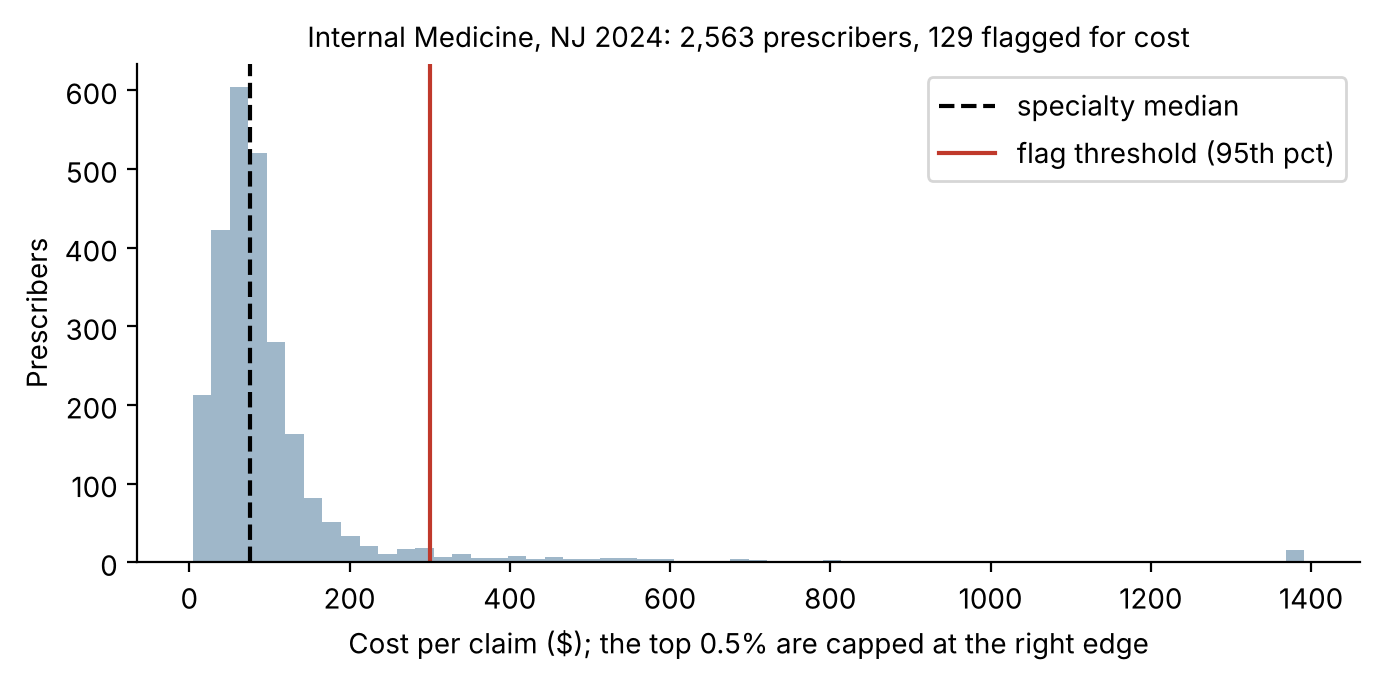

In [10]:
flags = pd.read_sql(text("SELECT * FROM vw_prescriber_flags"), eng)
spec = "Internal Medicine" if "Internal Medicine" in set(flags["specialty"]) else flags["specialty"].mode()[0]
s = flags[flags["specialty"] == spec]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(s["cost_per_claim"].clip(upper=s["cost_per_claim"].quantile(0.995)), bins=60, color="#9fb7c9")
cut = s.loc[s["high_cost"], "cost_per_claim"].min()
ax.axvline(s["specialty_median_cost_per_claim"].iloc[0], color="black", ls="--", label="specialty median")
if pd.notna(cut):
    ax.axvline(cut, color="#c0392b", label="flag threshold (95th pct)")
ax.set_xlabel("Cost per claim ($); the top 0.5% are capped at the right edge")
ax.set_ylabel("Prescribers")
ax.set_title(f"{spec}, NJ {latest}: {len(s):,} prescribers, {int(s['high_cost'].sum())} flagged for cost", fontsize=10)
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIG / "prescriber_cost_distribution.png", dpi=150)
plt.show()